In [27]:
import pandas as pd  # WHY: load chronological processed datasets
import numpy as np  # WHY: BiLSTM expects numerical arrays
import joblib  # WHY: reuse our fitted scaling logic

base = r"C:\sujit\SEM_5\SMART_GRID\processed_data"  # WHY: dataset location

X_train = pd.read_csv(base + r"\X_train.csv")
X_val = pd.read_csv(base + r"\X_val.csv")
X_test = pd.read_csv(base + r"\X_test.csv")

y_train = pd.read_csv(base + r"\y_train.csv").squeeze()
y_val = pd.read_csv(base + r"\y_val.csv").squeeze()
y_test = pd.read_csv(base + r"\y_test.csv").squeeze()

In [28]:
import joblib  # WHY: reload the scaler fitted only on training data

scaler = joblib.load(
    base + r"\price_scaler.pkl"
)  # WHY: prevent validation/test information from influencing scaling

X_train_scaled = scaler.transform(X_train)  # WHY: BiLSTM benefits from normalized inputs
X_val_scaled = scaler.transform(X_val)  # WHY: reuse training statistics only
X_test_scaled = scaler.transform(X_test)  # WHY: preserve unseen test distribution

print(X_train_scaled.shape)
print(X_val_scaled.shape)
print(X_test_scaled.shape)

(24427, 23)
(5234, 23)
(5235, 23)


In [29]:
def create_sequences(X, y, lookback=24):
    X_seq = []  # WHY: store each 24-hour feature sequence
    y_seq = []  # WHY: store its corresponding electricity-price target

    for i in range(lookback - 1, len(X)):
        X_seq.append(
            X[i - lookback + 1:i + 1]
        )  # WHY: sequence now ends with current-hour known features

        y_seq.append(
            y[i]
        )  # WHY: predict price for that same current hour

    return np.array(X_seq), np.array(y_seq)

In [30]:
lookback = 24  # WHY: give the BiLSTM one full day of historical behaviour

X_train_seq, y_train_seq = create_sequences(
    X_train_scaled,
    y_train.to_numpy(),
    lookback
)  # WHY: convert flat training rows into chronological windows

print("X train:", X_train_seq.shape)
print("y train:", y_train_seq.shape)

X train: (24404, 24, 23)
y train: (24404,)


In [31]:
val_X_context = np.vstack([
    X_train_scaled[-lookback:],
    X_val_scaled
])  # WHY: previous training hours are legitimate history for validation

val_y_context = np.concatenate([
    y_train.to_numpy()[-lookback:],
    y_val.to_numpy()
])  # WHY: maintain matching chronological targets

X_val_seq, y_val_seq = create_sequences(
    val_X_context, val_y_context, lookback
)

print("X validation:", X_val_seq.shape)
print("y validation:", y_val_seq.shape)

X validation: (5235, 24, 23)
y validation: (5235,)


In [32]:
test_X_context = np.vstack([
    X_val_scaled[-lookback:],
    X_test_scaled
])  # WHY: validation tail occurs before test and is valid historical context

test_y_context = np.concatenate([
    y_val.to_numpy()[-lookback:],
    y_test.to_numpy()
])  # WHY: maintain chronological alignment

X_test_seq, y_test_seq = create_sequences(
    test_X_context, test_y_context, lookback
)

print("X test:", X_test_seq.shape)
print("y test:", y_test_seq.shape)

X test: (5236, 24, 23)
y test: (5236,)


In [33]:
import tensorflow as tf  # WHY: provides Keras and recurrent neural-network layers

tf.keras.utils.set_random_seed(42)  # WHY: make this training run reproducible

bilstm_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(24, 23)),  # WHY: 24 hours, 23 features each
    tf.keras.layers.Bidirectional(
        tf.keras.layers.LSTM(64)
    ),  # WHY: learn temporal patterns across the 24-hour history
    tf.keras.layers.Dense(32, activation="relu"),  # WHY: refine temporal representation
    tf.keras.layers.Dense(1, activation="linear")  # WHY: continuous electricity price
])

bilstm_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_3 (Bidirectional) │ (None, 128)            │        45,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,217 (192.25 KB)

 Trainable params: 49,217 (192.25 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
bilstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),  # WHY: stable baseline optimizer
    loss="mse",  # WHY: penalize large forecasting errors
    metrics=["mae"]  # WHY: track interpretable average absolute error
)

In [35]:
bilstm_history = bilstm_model.fit(
    X_train_seq, y_train_seq,  # WHY: sequence-based training data
    validation_data=(X_val_seq, y_val_seq),  # WHY: choose using future validation period
    epochs=60,  # WHY: recurrent models usually need fewer but heavier epochs
    batch_size=64,  # WHY: reasonable balance of speed and stability
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",  # WHY: detect when generalization stops improving
        patience=8,  # WHY: avoid unnecessary long recurrent training
        restore_best_weights=True  # WHY: keep the best validation model
    )],
    verbose=1
)

Epoch 1/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 402.7723 - mae: 11.3963 - val_loss: 31.5774 - val_mae: 4.0730
Epoch 2/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 14.6366 - mae: 2.7832 - val_loss: 17.8281 - val_mae: 2.9776
Epoch 3/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 8.4626 - mae: 2.1309 - val_loss: 12.5041 - val_mae: 2.4570
Epoch 4/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 6.2972 - mae: 1.8378 - val_loss: 10.0074 - val_mae: 2.2023
Epoch 5/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 5.1453 - mae: 1.6560 - val_loss: 8.5754 - val_mae: 2.0188
Epoch 6/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 4.4933 - mae: 1.5395 - val_loss: 7.8004 - val_mae: 1.9089
Epoch 7/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 4.0926 - mae: 1.4606 - val_loss: 7.3255 - val_mae: 1.8312
Epoch 8/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 3.8726 - mae: 1.4143 - val_loss: 7.0009 - val_mae: 1.7782
Epoch 9/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/s

In [36]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

bilstm_val_pred = bilstm_model.predict(X_val_seq).flatten()

bilstm_val_mae = mean_absolute_error(y_val_seq, bilstm_val_pred)
bilstm_val_rmse = mean_squared_error(y_val_seq, bilstm_val_pred) ** 0.5
bilstm_val_r2 = r2_score(y_val_seq, bilstm_val_pred)

print(f"VAL MAE  : {bilstm_val_mae:.4f}")
print(f"VAL RMSE : {bilstm_val_rmse:.4f}")
print(f"VAL R²   : {bilstm_val_r2:.4f}")

164/164 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
VAL MAE  : 1.6156
VAL RMSE : 2.5102
VAL R²   : 0.9662


In [37]:
best_bilstm_epoch = np.argmin(
    bilstm_history.history["val_loss"]
) + 1  # WHY: identify the epoch with best validation performance

print("Best BiLSTM epoch:", best_bilstm_epoch)
print("Training stopped at:", len(bilstm_history.history["loss"]))

Best BiLSTM epoch: 21
Training stopped at: 29


In [38]:
lookback_48 = 48  # WHY: test whether two days of history improve forecasting

X_train_seq48, y_train_seq48 = create_sequences(
    X_train_scaled, y_train.to_numpy(), lookback_48
)  # WHY: convert training data into 48-hour windows

val_X48 = np.vstack([X_train_scaled[-lookback_48:], X_val_scaled])
val_y48 = np.concatenate([y_train.to_numpy()[-lookback_48:], y_val.to_numpy()])

X_val_seq48, y_val_seq48 = create_sequences(
    val_X48, val_y48, lookback_48
)  # WHY: preserve valid historical context before validation

print("Train:", X_train_seq48.shape)
print("Validation:", X_val_seq48.shape)

Train: (24380, 48, 23)
Validation: (5235, 48, 23)


In [39]:
tf.keras.utils.set_random_seed(42)  # WHY: keep comparison reproducible

bilstm48 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(48, 23)),  # WHY: 48 hours × 23 features
    tf.keras.layers.Bidirectional(
        tf.keras.layers.LSTM(64)
    ),  # WHY: same temporal model as 24-hour experiment
    tf.keras.layers.Dense(32, activation="relu"),  # WHY: same dense layer
    tf.keras.layers.Dense(1, activation="linear")  # WHY: continuous price output
])

bilstm48.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

In [40]:
history48 = bilstm48.fit(
    X_train_seq48, y_train_seq48,  # WHY: train using two-day sequences
    validation_data=(X_val_seq48, y_val_seq48),  # WHY: compare using validation
    epochs=60,  # WHY: maximum only; early stopping may finish sooner
    batch_size=64,  # WHY: keep previous BiLSTM batch size unchanged
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    )],  # WHY: prevent unnecessary overfitting
    verbose=1
)

Epoch 1/60
381/381 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - loss: 408.2811 - mae: 11.7695 - val_loss: 36.7903 - val_mae: 4.4009
Epoch 2/60
381/381 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 17.9106 - mae: 3.0622 - val_loss: 21.3997 - val_mae: 3.2864
Epoch 3/60
381/381 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 10.1401 - mae: 2.3230 - val_loss: 15.4419 - val_mae: 2.6748
Epoch 4/60
381/381 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 6.9876 - mae: 1.9258 - val_loss: 10.5589 - val_mae: 2.2489
Epoch 5/60
381/381 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 5.4091 - mae: 1.6842 - val_loss: 8.5335 - val_mae: 1.9991
Epoch 6/60
381/381 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 4.5762 - mae: 1.5386 - val_loss: 7.4775 - val_mae: 1.8554
Epoch 7/60
381/381 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 4.1396 - mae: 1.4530 - val_loss: 6.9004 - val_mae: 1.7648
Epoch 8/60
381/381 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 3.9059 - mae: 1.4045 - val_loss: 6.6075 - val_mae: 1.7164
Epoch 9/60
381/381 ━━━━━━━━━━━━━━━━━━━━

In [41]:
pred48 = bilstm48.predict(X_val_seq48).flatten()  # WHY: validation forecasts

mae48 = mean_absolute_error(y_val_seq48, pred48)
rmse48 = mean_squared_error(y_val_seq48, pred48) ** 0.5
r2_48 = r2_score(y_val_seq48, pred48)

print(f"VAL MAE  : {mae48:.4f}")
print(f"VAL RMSE : {rmse48:.4f}")
print(f"VAL R²   : {r2_48:.4f}")

164/164 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
VAL MAE  : 1.4911
VAL RMSE : 2.3690
VAL R²   : 0.9699


In [42]:
context = 47  # WHY: 48-hour window needs 47 previous rows + current row

val_X48 = np.vstack([
    X_train_scaled[-context:], X_val_scaled
])  # WHY: give first validation row its preceding 47 hours

val_y48 = np.concatenate([
    y_train.to_numpy()[-context:], y_val.to_numpy()
])  # WHY: keep features and targets aligned

X_val_seq48, y_val_seq48 = create_sequences(
    val_X48, val_y48, 48
)  # WHY: should now produce exactly one sequence per validation row

print(X_val_seq48.shape, y_val_seq48.shape)

(5234, 48, 23) (5234,)


In [43]:
X_final = pd.concat([X_train, X_val], ignore_index=True)  # WHY: validation is now training data
y_final = pd.concat([y_train, y_val], ignore_index=True)  # WHY: keep targets aligned

from sklearn.preprocessing import StandardScaler

final_bilstm_scaler = StandardScaler()  # WHY: fit preprocessing on all non-test data
X_final_scaled = final_bilstm_scaler.fit_transform(X_final)
X_test_scaled_final = final_bilstm_scaler.transform(X_test)  # WHY: test stays unseen

X_final_seq, y_final_seq = create_sequences(
    X_final_scaled, y_final.to_numpy(), 48
)  # WHY: train final model using 48-hour sequences

In [44]:
context = 47  # WHY: previous 47 rows + current test row form 48-hour input

test_X_context = np.vstack([
    X_final_scaled[-context:], X_test_scaled_final
])  # WHY: provide legitimate history before the test period

test_y_context = np.concatenate([
    y_final.to_numpy()[-context:], y_test.to_numpy()
])  # WHY: maintain exact chronological alignment

X_test_seq_final, y_test_seq_final = create_sequences(
    test_X_context, test_y_context, 48
)

print(X_test_seq_final.shape, y_test_seq_final.shape)

(5235, 48, 23) (5235,)


In [45]:
best_epoch_48 = np.argmin(
    history48.history["val_loss"]
) + 1  # WHY: use the training duration that generalized best

print("Best epoch:", best_epoch_48)

Best epoch: 38


In [46]:
tf.keras.utils.set_random_seed(42)  # WHY: reproducible final model

final_bilstm = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(48, 23)),  # WHY: selected two-day lookback
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1, activation="linear")
])

final_bilstm.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="mse",
    metrics=["mae"]
)

In [47]:
final_bilstm.fit(
    X_final_seq,
    y_final_seq,
    epochs=best_epoch_48,  # WHY: duration selected using validation
    batch_size=64,  # WHY: keep validated BiLSTM configuration
    verbose=1
)

Epoch 1/38
463/463 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - loss: 340.5555 - mae: 10.2220
Epoch 2/38
463/463 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 13.9063 - mae: 2.6859
Epoch 3/38
463/463 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 8.1838 - mae: 2.0517
Epoch 4/38
463/463 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 5.9806 - mae: 1.7407
Epoch 5/38
463/463 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 4.9746 - mae: 1.5775
Epoch 6/38
463/463 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 4.4809 - mae: 1.4882
Epoch 7/38
463/463 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 4.2457 - mae: 1.4421
Epoch 8/38
463/463 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 4.1016 - mae: 1.4133
Epoch 9/38
463/463 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 4.0038 - mae: 1.3938
Epoch 10/38
463/463 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 3.9311 - mae: 1.3786
Epoch 11/38
463/463 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 3.8763 - mae: 1.3669
Epoch 12/38
463/463 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - loss: 3.8254 - mae: 1.3570
Epoch 13/

In [48]:
bilstm_test_pred = final_bilstm.predict(X_test_seq_final).flatten()

bilstm_mae = mean_absolute_error(y_test_seq_final, bilstm_test_pred)
bilstm_rmse = mean_squared_error(y_test_seq_final, bilstm_test_pred) ** 0.5
bilstm_r2 = r2_score(y_test_seq_final, bilstm_test_pred)

actual = y_test_seq_final  # WHY: simplify MAPE calculation
nonzero = actual != 0  # WHY: avoid division by zero
bilstm_mape = np.mean(np.abs((actual[nonzero] - bilstm_test_pred[nonzero])
                             / actual[nonzero])) * 100

print(f"FINAL BiLSTM MAE  : {bilstm_mae:.4f}")
print(f"FINAL BiLSTM RMSE : {bilstm_rmse:.4f}")
print(f"FINAL BiLSTM MAPE : {bilstm_mape:.2f}%")
print(f"FINAL BiLSTM R²   : {bilstm_r2:.4f}")

164/164 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
FINAL BiLSTM MAE  : 1.1227
FINAL BiLSTM RMSE : 1.6019
FINAL BiLSTM MAPE : 1.65%
FINAL BiLSTM R²   : 0.9590


In [49]:
import os  # WHY: ensure deployment-artifact folder exists
import joblib  # WHY: save the exact scaler required by the BiLSTM

os.makedirs("saved_models", exist_ok=True)  # WHY: keep model artifacts together

final_bilstm.save(
    "saved_models/price_bilstm.keras"
)  # WHY: preserve trained architecture and weights

joblib.dump(
    final_bilstm_scaler,
    "saved_models/price_bilstm_scaler.pkl"
)  # WHY: inference must reproduce training preprocessing

print("Final BiLSTM and scaler saved.")

Final BiLSTM and scaler saved.


In [50]:
import pandas as pd  # WHY: create a readable comparison table
import numpy as np  # WHY: calculate absolute errors

actual = np.asarray(y_test_seq_final).flatten()  # WHY: ensure 1-D actual prices
predicted = np.asarray(bilstm_test_pred).flatten()  # WHY: ensure 1-D predictions

comparison = pd.DataFrame({
    "Actual_Price": actual,
    "Predicted_Price": predicted
})  # WHY: align actual and predicted prices row-by-row

comparison["Error"] = comparison["Actual_Price"] - comparison["Predicted_Price"]
comparison["Absolute_Error"] = np.abs(comparison["Error"])  # WHY: error magnitude

print(comparison.head(20))  # WHY: inspect first 20 unseen test predictions

    Actual_Price  Predicted_Price     Error  Absolute_Error
0          70.19        71.951530 -1.761530        1.761530
1          67.31        67.752472 -0.442472        0.442472
2          68.05        65.513870  2.536130        2.536130
3          65.97        64.837166  1.132834        1.132834
4          57.81        60.661049 -2.851049        2.851049
5          56.88        56.759262  0.120738        0.120738
6          57.40        56.822678  0.577322        0.577322
7          57.92        58.104286 -0.184286        0.184286
8          65.66        63.615738  2.044262        2.044262
9          68.70        67.587151  1.112849        1.112849
10         70.13        71.725212 -1.595212        1.595212
11         71.36        70.450882  0.909118        0.909118
12         71.11        72.136406 -1.026406        1.026406
13         72.53        72.620018 -0.090018        0.090018
14         72.69        73.566383 -0.876383        0.876383
15         72.21        72.739479 -0.529

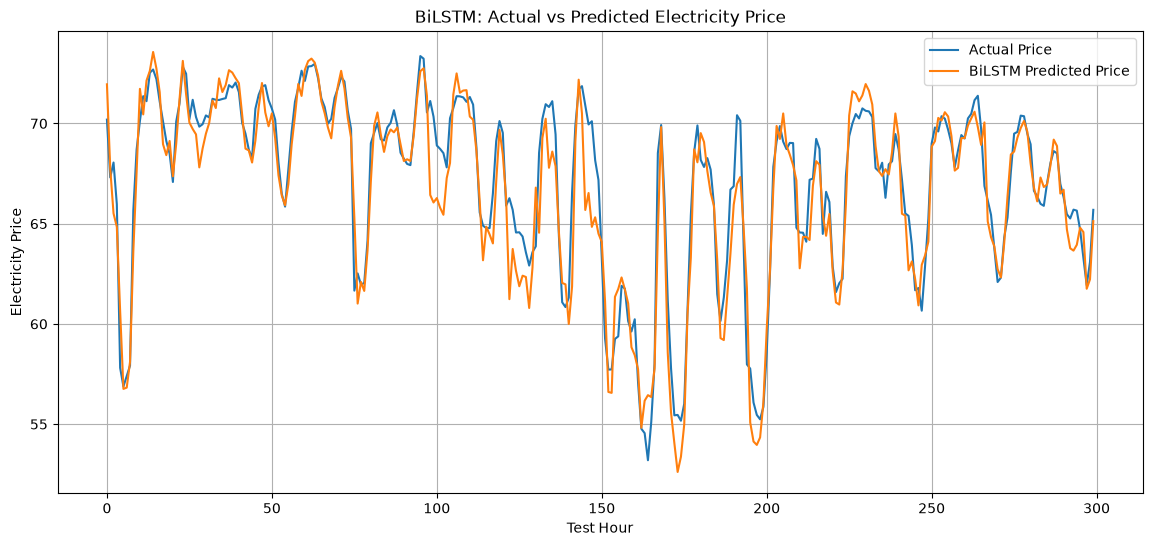

In [51]:
import matplotlib.pyplot as plt  # WHY: visually compare forecasting performance

samples = 300  # WHY: ~12.5 days gives a readable graph

plt.figure(figsize=(14, 6))
plt.plot(actual[:samples], label="Actual Price")
plt.plot(predicted[:samples], label="BiLSTM Predicted Price")

plt.xlabel("Test Hour")
plt.ylabel("Electricity Price")
plt.title("BiLSTM: Actual vs Predicted Electricity Price")
plt.legend()
plt.grid(True)
plt.show()

In [52]:
comparison.to_csv(
    "saved_models/bilstm_actual_vs_predicted.csv",
    index=False
)  # WHY: preserve every test prediction for analysis/reporting

print("Comparison saved successfully.")

Comparison saved successfully.
